# CA4

### Group 3

Group members:

- Zaur Kambiev
- Vinicius Millan Santa Catharina
- Stig Espen Paulsberg


### Imports

In [2]:
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt

from skrub import TableReport


ModuleNotFoundError: No module named 'seaborn'

### Reading data

In [ ]:
df = pd.read_csv(r"dat-200-ca-4-h-2026\trainCA4DAT200.csv").drop(columns='CustomerId')

### Data exploration and visualisation

In [ ]:
TableReport(df)

NameError: name 'TableReport' is not defined

In [ ]:
df.head()

,State,AccountLength,AreaCode,InternationalPlan,VoiceMailPlan,NumVoiceMailMessages,DayMinutes,DayCalls,DayCharge,EveMinutes,EveCalls,EveCharge,NightMinutes,NightCalls,NightCharge,IntlMinutes,IntlCalls,IntlCharge,CustomerServiceCalls,Churn
0,NJ,87,510,no,no,0,223.2,109,37.94,127.5,86,10.84,289.3,83,13.02,14.5,4,3.92,3,0
1,RI,114,510,no,yes,28,225.8,94,38.39,193.0,117,16.41,232.4,100,10.46,8.4,9,2.27,4,0
2,ND,55,415,no,no,0,180.1,77,30.62,235.5,98,20.02,169.4,104,7.62,11.1,2,3.00,0,0
3,DC,100,510,yes,no,0,68.5,110,11.65,337.1,115,28.65,205.2,99,9.23,12.1,9,3.27,0,0
4,AL,74,408,no,yes,46,277.7,109,47.21,270.0,114,22.95,165.3,82,7.44,10.4,2,2.81,1,0


In [ ]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3500 entries, 0 to 3499
Data columns (total 20 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   State                 3500 non-null   str    
 1   AccountLength         3500 non-null   int64  
 2   AreaCode              3500 non-null   int64  
 3   InternationalPlan     3500 non-null   str    
 4   VoiceMailPlan         3500 non-null   str    
 5   NumVoiceMailMessages  3500 non-null   int64  
 6   DayMinutes            3500 non-null   float64
 7   DayCalls              3500 non-null   int64  
 8   DayCharge             3500 non-null   float64
 9   EveMinutes            3500 non-null   float64
 10  EveCalls              3500 non-null   int64  
 11  EveCharge             3500 non-null   float64
 12  NightMinutes          3500 non-null   float64
 13  NightCalls            3500 non-null   int64  
 14  NightCharge           3500 non-null   float64
 15  IntlMinutes           3500 non-n

In [ ]:
df['AreaCode'].nunique()

3

In [ ]:
numerical_features = [
    'AccountLength',
    'NumVoiceMailMessages',
    'DayMinutes',
    'DayCalls',
    'DayCharge',
    'EveMinutes',
    'EveCalls',
    'EveCharge',
    'NightMinutes',
    'NightCalls',
    'NightCharge',
    'IntlMinutes',
    'IntlCalls',
    'IntlCharge',
    'CustomerServiceCalls'
]

categorical_features = [
    'State',
    'AreaCode',
    'InternationalPlan',
    'VoiceMailPlan',
    'Churn'
]

In [ ]:
print(df[numerical_features].info())

<class 'pandas.DataFrame'>
RangeIndex: 3500 entries, 0 to 3499
Data columns (total 15 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   AccountLength         3500 non-null   int64  
 1   NumVoiceMailMessages  3500 non-null   int64  
 2   DayMinutes            3500 non-null   float64
 3   DayCalls              3500 non-null   int64  
 4   DayCharge             3500 non-null   float64
 5   EveMinutes            3500 non-null   float64
 6   EveCalls              3500 non-null   int64  
 7   EveCharge             3500 non-null   float64
 8   NightMinutes          3500 non-null   float64
 9   NightCalls            3500 non-null   int64  
 10  NightCharge           3500 non-null   float64
 11  IntlMinutes           3500 non-null   float64
 12  IntlCalls             3500 non-null   int64  
 13  IntlCharge            3500 non-null   float64
 14  CustomerServiceCalls  3500 non-null   int64  
dtypes: float64(8), int64(7)
memory u

Check for missing values

In [ ]:
print(df.isna().sum())

State                   0
AccountLength           0
AreaCode                0
InternationalPlan       0
VoiceMailPlan           0
NumVoiceMailMessages    0
DayMinutes              0
DayCalls                0
DayCharge               0
EveMinutes              0
EveCalls                0
EveCharge               0
NightMinutes            0
NightCalls              0
NightCharge             0
IntlMinutes             0
IntlCalls               0
IntlCharge              0
CustomerServiceCalls    0
Churn                   0
dtype: int64


Check for duplicated values

In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
# sns.pairplot(
#     data=df.drop(columns=['State', 'AreaCode', 'InternationalPlan', 'VoiceMailPlan']),
#     hue='Churn'
# )

#### Box plots

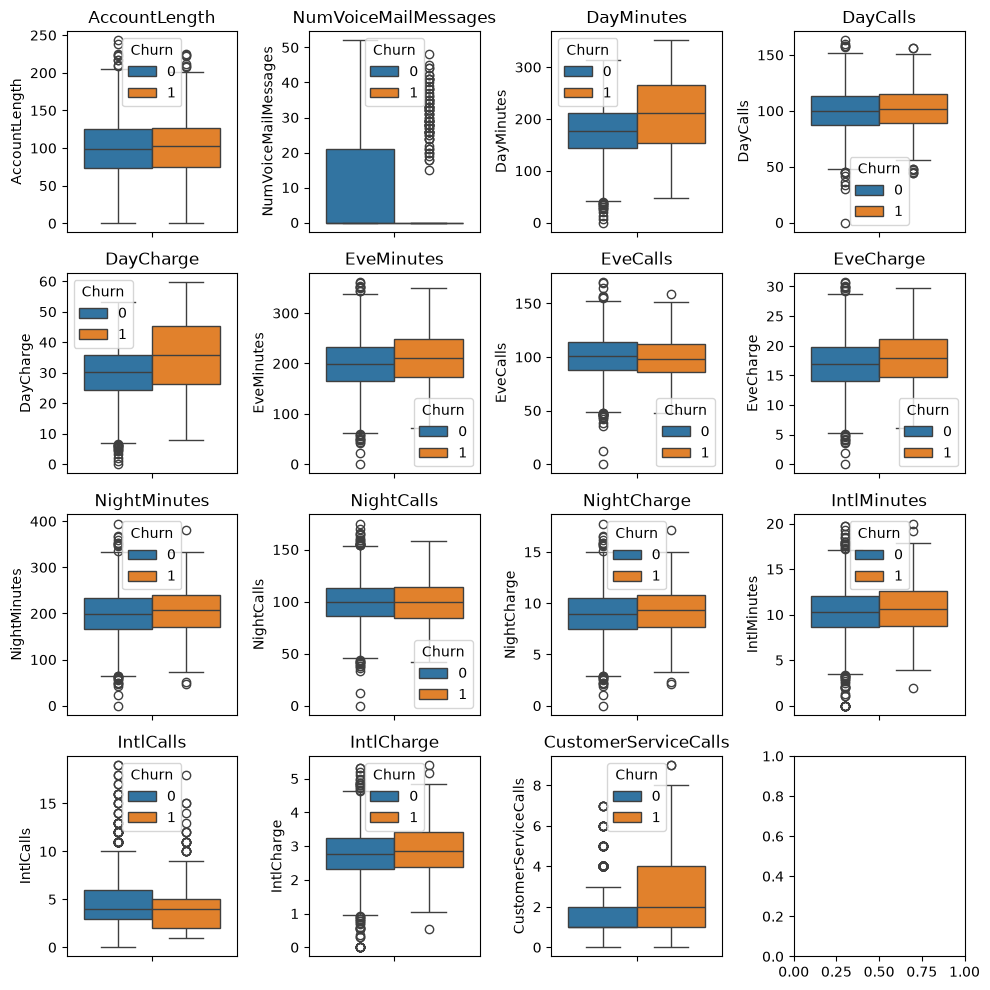

In [ ]:
fig, axes = plt.subplots(4, 4, figsize=(10, 10))
axes = axes.ravel()

for i, feature in enumerate(numerical_features):
    sns.boxplot(
        data=df,
        y=feature,
        ax=axes[i],
        hue='Churn'
    )
    axes[i].set_title(feature)
    
plt.tight_layout()
plt.show()

#### Heatmap

Must clean data before visualising

#### Outliers

Not sure if we should keep it. Outliers might be the most important part for this dataset actually. Need to discuss further.

In [ ]:
# for feature in numerical_features:
#     # z threshold
#     z_threshold = 3
    
#     # Create figure with 2 subplots for each feature
#     fig, axes = plt.subplots(1, 2, figsize=(12, 6))
    
#     # Plot before outliers removal
#     axes[0].hist(
#         df[feature],
#         bins=30,
#         alpha=0.7,
#         color='blue'
#     )
#     axes[0].set_title(f'{feature} - Before removal of outliers')
#     axes[0].set_xlabel(feature)
#     axes[0].set_ylabel('Frequency')
    
#     # Z-score
#     z_score = (df[feature] - np.mean(df[feature])) / (np.std(df[feature] + 1e-10))
    
#     # Plot after outlier removal
#     df_clean = df[np.abs(z_score) <= z_threshold]
#     axes[1].hist(
#         df_clean[feature],
#         bins=30,
#         alpha=0.7,
#         color='green'
#     )
#     axes[1].set_title(f'{feature} - After removal of outliers')
#     axes[1].set_xlabel(feature)
#     axes[1].set_ylabel('Frequency')
    
#     plt.tight_layout()
#     plt.show()
#     # plt.savefig(f"{feature}.png")
#     plt.close(fig)
    

#### Summary

Numerical features looks ok regarding correct datatype. Categorical features needs some processing. We need to change from yes/no to 1/0.
There are no missing values, and no duplicated values.
*AreaCode* has 3 unique values, so it might be useful to one hot encode this feature.
Need to check for outliers as well.

Haven't decided if cleaning up regarding outliers is a good idea.

### Data cleaning

One hot encoding

In [ ]:
# One-hot-encode column AreaCode
df = pd.get_dummies(
    df,
    columns=['AreaCode']
)

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3500 entries, 0 to 3499
Data columns (total 22 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   State                 3500 non-null   str    
 1   AccountLength         3500 non-null   int64  
 2   InternationalPlan     3500 non-null   str    
 3   VoiceMailPlan         3500 non-null   str    
 4   NumVoiceMailMessages  3500 non-null   int64  
 5   DayMinutes            3500 non-null   float64
 6   DayCalls              3500 non-null   int64  
 7   DayCharge             3500 non-null   float64
 8   EveMinutes            3500 non-null   float64
 9   EveCalls              3500 non-null   int64  
 10  EveCharge             3500 non-null   float64
 11  NightMinutes          3500 non-null   float64
 12  NightCalls            3500 non-null   int64  
 13  NightCharge           3500 non-null   float64
 14  IntlMinutes           3500 non-null   float64
 15  IntlCalls             3500 non-n

Correct categories for features

In [ ]:
# Change category values yes/no to 1/0. 
df[['InternationalPlan', 'VoiceMailPlan']] = df[['InternationalPlan', 'VoiceMailPlan']].replace({
    'yes': 1,
    'no': 0,
})

df = df.astype(
    {
        'State': 'category',
        'InternationalPlan': 'bool',
        'VoiceMailPlan': 'bool',
        'Churn': 'bool'
    }
)

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3500 entries, 0 to 3499
Data columns (total 22 columns):
 #   Column                Non-Null Count  Dtype   
---  ------                --------------  -----   
 0   State                 3500 non-null   category
 1   AccountLength         3500 non-null   int64   
 2   InternationalPlan     3500 non-null   bool    
 3   VoiceMailPlan         3500 non-null   bool    
 4   NumVoiceMailMessages  3500 non-null   int64   
 5   DayMinutes            3500 non-null   float64 
 6   DayCalls              3500 non-null   int64   
 7   DayCharge             3500 non-null   float64 
 8   EveMinutes            3500 non-null   float64 
 9   EveCalls              3500 non-null   int64   
 10  EveCharge             3500 non-null   float64 
 11  NightMinutes          3500 non-null   float64 
 12  NightCalls            3500 non-null   int64   
 13  NightCharge           3500 non-null   float64 
 14  IntlMinutes           3500 non-null   float64 
 15  IntlCalls      

### Data exploration & visualisation after cleaning

##### Heatmap

In [ ]:
sns.heatmap(
    df.drop(columns='State').corr(),
    annot=True,
    fmt='.1f',
    annot_kws={
        'size': 6
    }
)

Smaller heatmap

In [ ]:
selected_features = [
    'Churn',
    'VoiceMailPlan',
    'NumVoiceMailMessages',
    'DayMinutes',
    'DayCharge',
    'EveMinutes',
    'EveCharge',
    'NightMinutes',
    'NightCharge',
    'IntlMinutes',
    'IntlCharge',
    'AreaCode_408',
    'AreaCode_415',
    'AreaCode_510'
]

sns.heatmap(
    df[selected_features].corr(),
    annot=True,
    fmt=".2f",
    annot_kws={
        'size': 7,
    }
)

##### Summary

We can remove the feature regarding minutes for Day, Eve, Night, and Intl.

Regarding *VoiceMailPlan* and *NumVoiceMailMessages*, maybe *NumVoiceMailMessages* because it is easier to interpret a yes or no feature than a continuous one (?). Might depend on the choice of model?

### Preprocessing

### Evaluating models/hyperparameters (cross-validation)

### Kaggle submission